# Proyecto Pre-procesamiento de datos
Nombres: Santiago Galeano y Alejandra Rodríguez

In [ ]:
#Paso 1. Importamos las librerías:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap
import plotly.express as px
from sklearn.neighbors import LocalOutlierFactor
from google.colab import drive
from sklearn.preprocessing import MinMaxScaler

In [ ]:
#Paso 2. Cargamos los datos:
df = pd.read_csv('/content/hotel_bookings.csv')
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
#Paso 3. Conociendo los datos:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
#Paso 4. Identificar los tipos de datos:
df.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [ ]:
#Paso 5. Identificar datos faltantes:
df.isnull().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


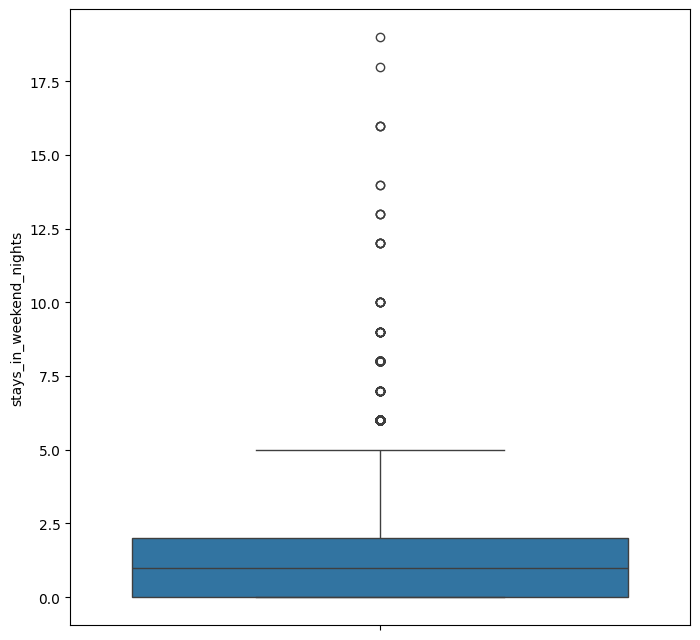

In [ ]:
fig = plt.figure(figsize=( 8 , 8 ))
sns.boxplot(y=df[ "stays_in_weekend_nights" ])
plt.show()


<Axes: xlabel='is_canceled', ylabel='stays_in_weekend_nights'>

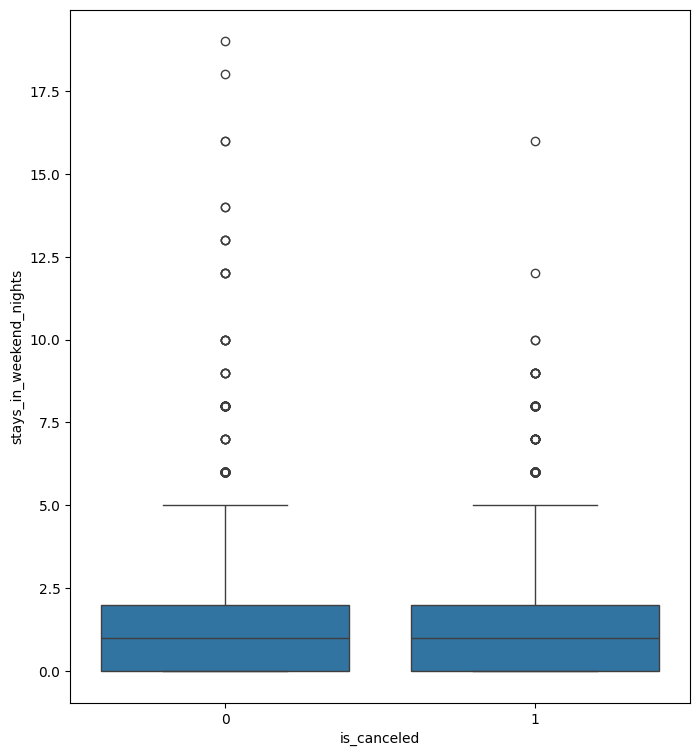

In [ ]:
fig = plt.figure(figsize=( 8 , 9 ))
sns.boxplot(x= "is_canceled" , y= "stays_in_weekend_nights" , data=df)


In [ ]:
# Paso 7. Calcular las estadísticas
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
include=[ 'object' ]
df.describe(include=[ 'object' ])

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


<function matplotlib.pyplot.show(close=None, block=None)>

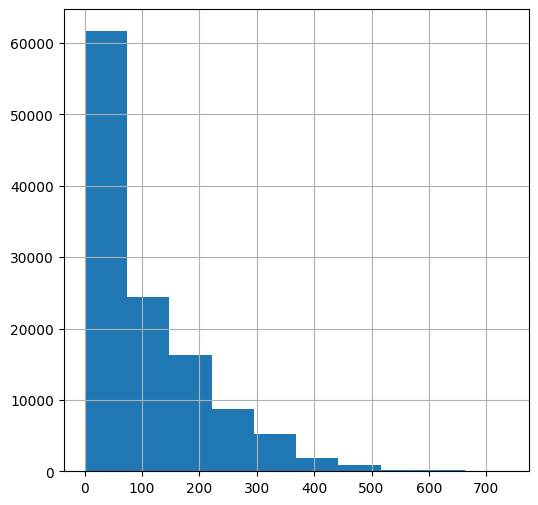

In [ ]:
#Paso 8. Análisis de tendencia central, posición y dispersión:
df[ 'lead_time' ].hist(figsize = ( 6 , 6 ))
plt.show


In [ ]:
media = df[ 'lead_time' ].mean()
mediana = df[ 'lead_time' ].median()
moda = df[ 'lead_time' ].mode()
sesgo = df[ 'lead_time' ].skew()
kurt = df[ 'lead_time' ].kurt()
print ( "La media es:" , media)
print ( "La mediana es:" , mediana)
print ( "La moda es:" , moda)
print ( "El sesgo es:" , sesgo)
print ( "La curtosis es:" , kurt)


La media es: 104.01141636652986
La mediana es: 69.0
La moda es: 0    0
Name: lead_time, dtype: int64
El sesgo es: 1.3465498727254268
La curtosis es: 1.6964488485585467


<function matplotlib.pyplot.show(close=None, block=None)>

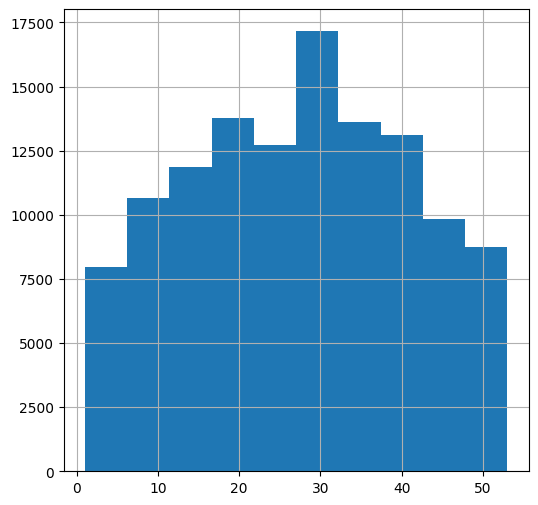

In [ ]:
Arrival_date_week_number: "número de la semana del año en que llega el huesped al hotel."
df[ 'arrival_date_week_number' ].hist(figsize = ( 6 , 6 ))
plt.show


In [ ]:
media = df[ 'arrival_date_week_number' ].mean()
mediana = df[ 'arrival_date_week_number' ].median()
moda = df[ 'arrival_date_week_number' ].mode()
sesgo = df[ 'arrival_date_week_number' ].skew()
kurt = df[ 'arrival_date_week_number' ].kurt()

print ( "La media es:" , media)
print ( "La mediana es:" , mediana)
print ( "La moda es:" , moda)
print ( "El sesgo es:" , sesgo)
print ( "La curtosis es:" , kurt)

La media es: 27.16517296255968
La mediana es: 28.0
La moda es: 0    33
Name: arrival_date_week_number, dtype: int64
El sesgo es: -0.010014326041540811
La curtosis es: -0.9860771763295451


In [ ]:
# Paso 9. Contando datos duplicados
df.duplicated().sum()

np.int64(31994)

KeyError: 'Arrival_date_week_number'

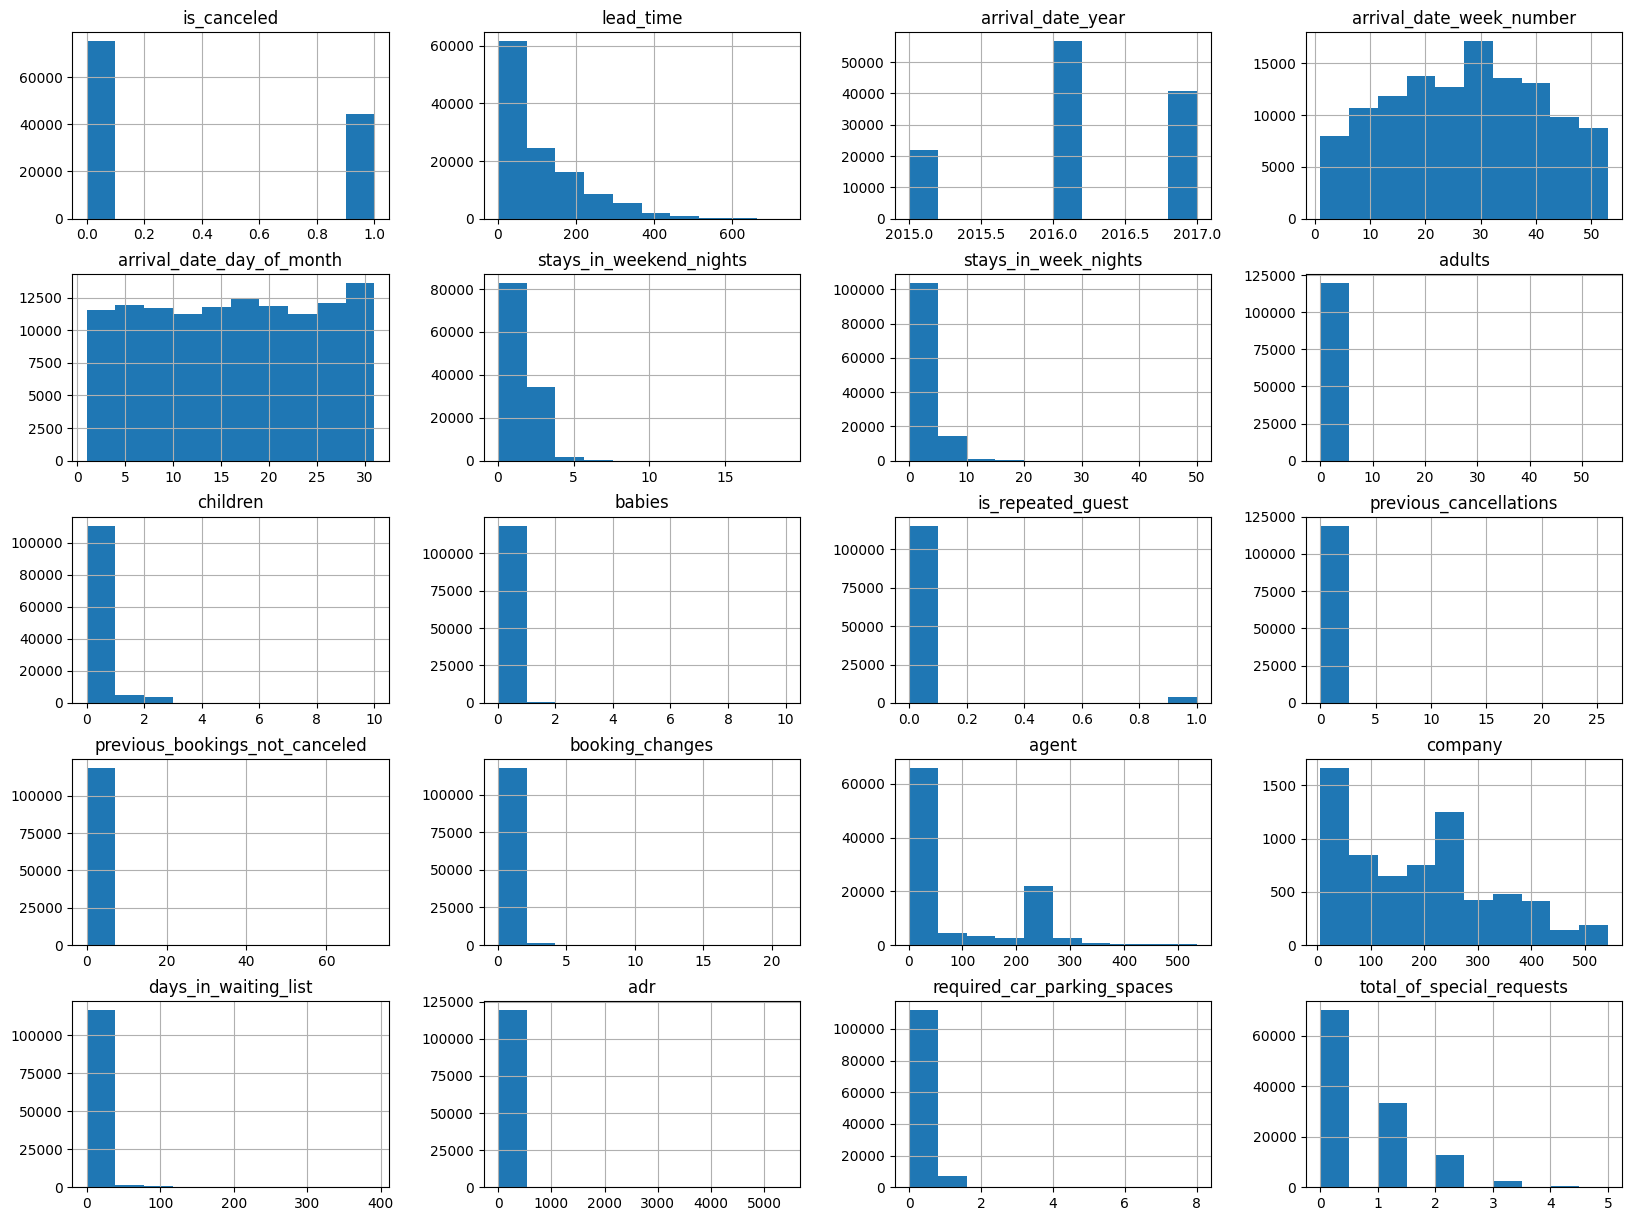

In [ ]:
# Paso 10. Exploración y visualización de los datos
#10.1
df.hist(figsize=( 20 , 15 ))
df[ 'Arrival_date_week_number' ].hist(figsize = ( 6 , 6 ))
plt.xlabel( 'arrival_date_week_number' )
plt.ylabel( 'Cantidad' )
plt.title( 'Histograma fecha_llegada_número_semana' , fontweight = "bold" )
plt.show

In [ ]:
#10.2. Análisis de variables categóricas:
df_cat = df.select_dtypes(include=[ 'object' ])
df_cat.head()


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
0,Resort Hotel,July,BB,PRT,Direct,Direct,C,C,No Deposit,Transient,Check-Out,2015-07-01
1,Resort Hotel,July,BB,PRT,Direct,Direct,C,C,No Deposit,Transient,Check-Out,2015-07-01
2,Resort Hotel,July,BB,GBR,Direct,Direct,A,C,No Deposit,Transient,Check-Out,2015-07-02
3,Resort Hotel,July,BB,GBR,Corporate,Corporate,A,A,No Deposit,Transient,Check-Out,2015-07-02
4,Resort Hotel,July,BB,GBR,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-07-03


<function matplotlib.pyplot.show(close=None, block=None)>

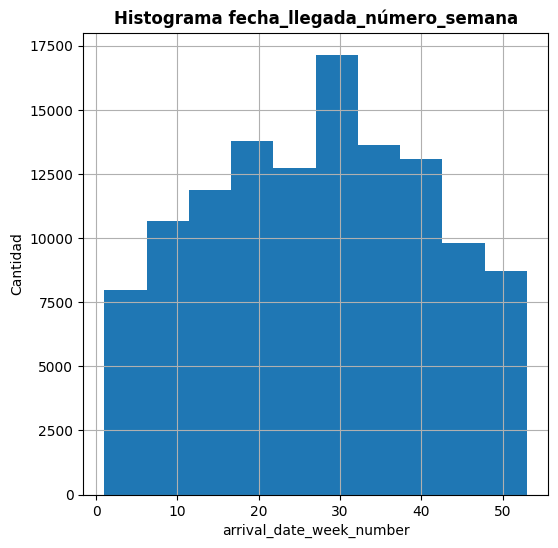

In [ ]:
df[ 'arrival_date_week_number' ].hist(figsize = ( 6 , 6 ))
plt.xlabel( 'arrival_date_week_number' )
plt.ylabel( 'Cantidad' )
plt.title( 'Histograma fecha_llegada_número_semana' , fontweight = "bold" )
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

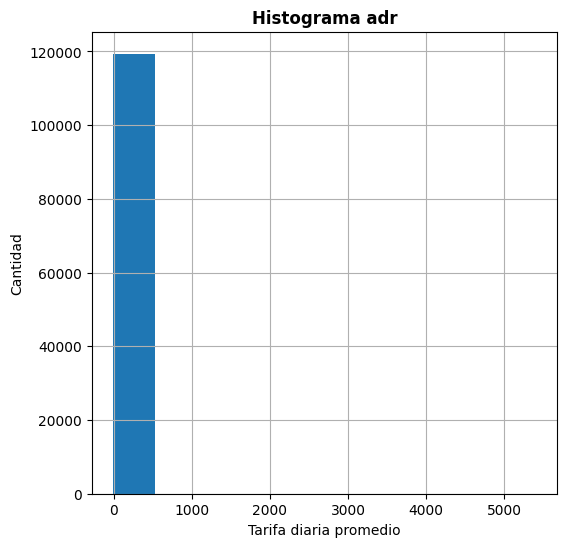

In [ ]:
df[ 'adr' ].hist(figsize = ( 6 , 6 ))
plt.xlabel( 'Tarifa diaria promedio' )
plt.ylabel( 'Cantidad' )
plt.title( 'Histograma adr' , fontweight = "bold" )
plt.show

<Axes: xlabel='arrival_date_month', ylabel='adr'>

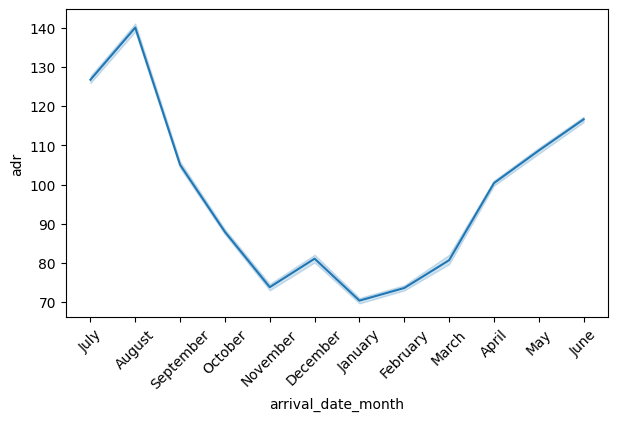

In [ ]:
fig = plt.figure(figsize=( 7 , 4 ), dpi= 100 )
plt.xticks(rotation = 45 , fontweight= 10 )
sns.lineplot(data=df, x = 'arrival_date_month' , y = 'adr' )

<Axes: xlabel='arrival_date_week_number', ylabel='adr'>

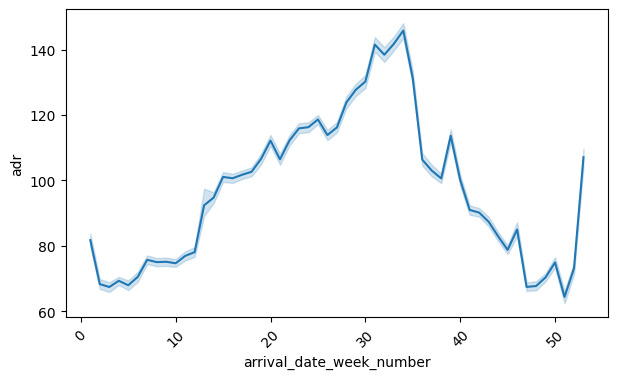

In [ ]:
fig = plt.figure(figsize=( 7 , 4 ), dpi= 100 )
plt.xticks(rotation = 45 , fontweight= 10 )
sns.lineplot(data=df, x = 'arrival_date_week_number' , y = 'adr' )

In [ ]:
for col in df_cat.columns:
  print ( f" {col} : \n {df_cat[col].unique()} \n" )


 hotel : 
 ['Resort Hotel' 'City Hotel'] 

 arrival_date_month : 
 ['July' 'August' 'September' 'October' 'November' 'December' 'January'
 'February' 'March' 'April' 'May' 'June'] 

 meal : 
 ['BB' 'FB' 'HB' 'SC' 'Undefined'] 

 country : 
 ['PRT' 'GBR' 'USA' 'ESP' 'IRL' 'FRA' nan 'ROU' 'NOR' 'OMN' 'ARG' 'POL'
 'DEU' 'BEL' 'CHE' 'CN' 'GRC' 'ITA' 'NLD' 'DNK' 'RUS' 'SWE' 'AUS' 'EST'
 'CZE' 'BRA' 'FIN' 'MOZ' 'BWA' 'LUX' 'SVN' 'ALB' 'IND' 'CHN' 'MEX' 'MAR'
 'UKR' 'SMR' 'LVA' 'PRI' 'SRB' 'CHL' 'AUT' 'BLR' 'LTU' 'TUR' 'ZAF' 'AGO'
 'ISR' 'CYM' 'ZMB' 'CPV' 'ZWE' 'DZA' 'KOR' 'CRI' 'HUN' 'ARE' 'TUN' 'JAM'
 'HRV' 'HKG' 'IRN' 'GEO' 'AND' 'GIB' 'URY' 'JEY' 'CAF' 'CYP' 'COL' 'GGY'
 'KWT' 'NGA' 'MDV' 'VEN' 'SVK' 'FJI' 'KAZ' 'PAK' 'IDN' 'LBN' 'PHL' 'SEN'
 'SYC' 'AZE' 'BHR' 'NZL' 'THA' 'DOM' 'MKD' 'MYS' 'ARM' 'JPN' 'LKA' 'CUB'
 'CMR' 'BIH' 'MUS' 'COM' 'SUR' 'UGA' 'BGR' 'CIV' 'JOR' 'SYR' 'SGP' 'BDI'
 'SAU' 'VNM' 'PLW' 'QAT' 'EGY' 'PER' 'MLT' 'MWI' 'ECU' 'MDG' 'ISL' 'UZB'
 'NPL' 'BHS' 'MAC' 'TGO' 'TWN' '

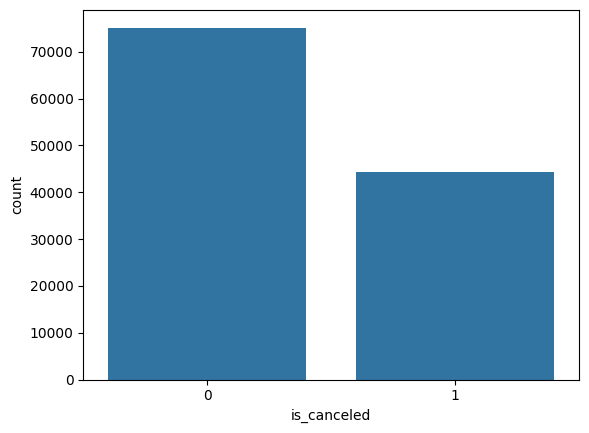

In [ ]:
sns.countplot(data=df, x = 'is_canceled' )
plt.show()


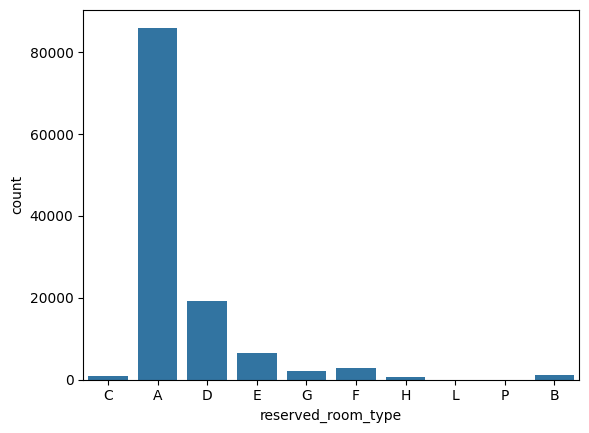

In [ ]:
sns.countplot(data=df, x = 'reserved_room_type' )
plt.show()


([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, 'Direct'),
  Text(1, 0, 'Corporate'),
  Text(2, 0, 'Online TA'),
  Text(3, 0, 'Offline TA/TO'),
  Text(4, 0, 'Complementary'),
  Text(5, 0, 'Groups'),
  Text(6, 0, 'Undefined'),
  Text(7, 0, 'Aviation')])

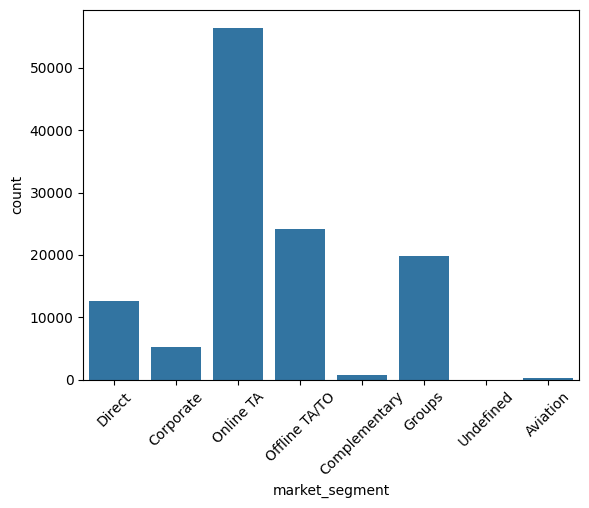

In [ ]:
sns.countplot(data=df, x= 'market_segment' )
plt.xticks(rotation= 45 , fontweight= 10 )


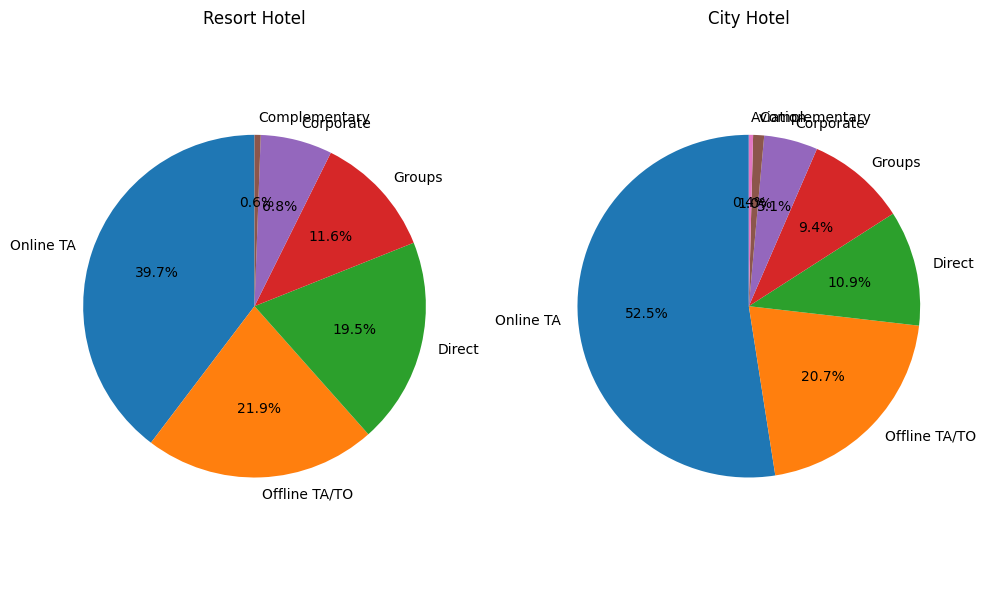

In [ ]:
#Separamos los grupos por tipo de hotel y solo con reservas no canceladas:
rh = df[(df['hotel'] == 'Resort Hotel') & (df['is_canceled'] == 0)].copy()
ch = df[(df['hotel'] == 'City Hotel') & (df['is_canceled'] == 0)].copy()

rh_counts= rh[ 'market_segment' ].value_counts(dropna=False)
ch_counts= ch[ 'market_segment' ].value_counts(dropna=False)

#Ajustamos el tamaño de la figura:
fig, axes = plt.subplots(1, 2, figsize = ( 10 , 6 ))


axes[0].pie(rh_counts, labels=rh_counts.index, autopct='%.1f%%', startangle=90)
axes[0].set_title('Resort Hotel')
axes[0].axis('equal')

axes[1].pie(ch_counts.values, labels=ch_counts.index, autopct='%.1f%%', startangle=90)
axes[1].set_title('City Hotel')
axes[1].axis('equal')

plt.tight_layout()
plt.show()

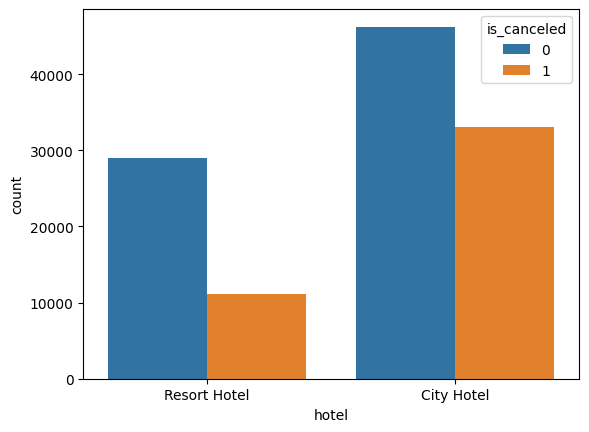

In [ ]:
# Paso 12. Combinando variables
sns.countplot(data=df, x = 'hotel' , hue= 'is_canceled' )
plt.show()

In [ ]:
paises_mas_visitas = df[df[ 'is_canceled' ] == 0 ][ 'country' ].value_counts().reset_index()
paises_mas_visitas.columns = [ 'country' , 'Número de invitados' ]
paises_mas_visitas

,country,Número de invitados
0,PRT,21071
1,GBR,9676
2,FRA,8481
3,ESP,6391
4,DEU,6069
...,...,...
160,KIR,1
161,ATF,1
162,TJK,1
163,SLE,1


In [ ]:
import plotly.express as px

# Mapa coroplético simple (plotly)
fig = px.choropleth(paises_mas_visitas,
                    locations = 'country',
                    color = 'Número de invitados',
                    hover_name = 'country',
                    color_continuous_scale = 'Portland')
fig.update_layout(title = 'Visitantes por país (no canceladas)')
fig.show()

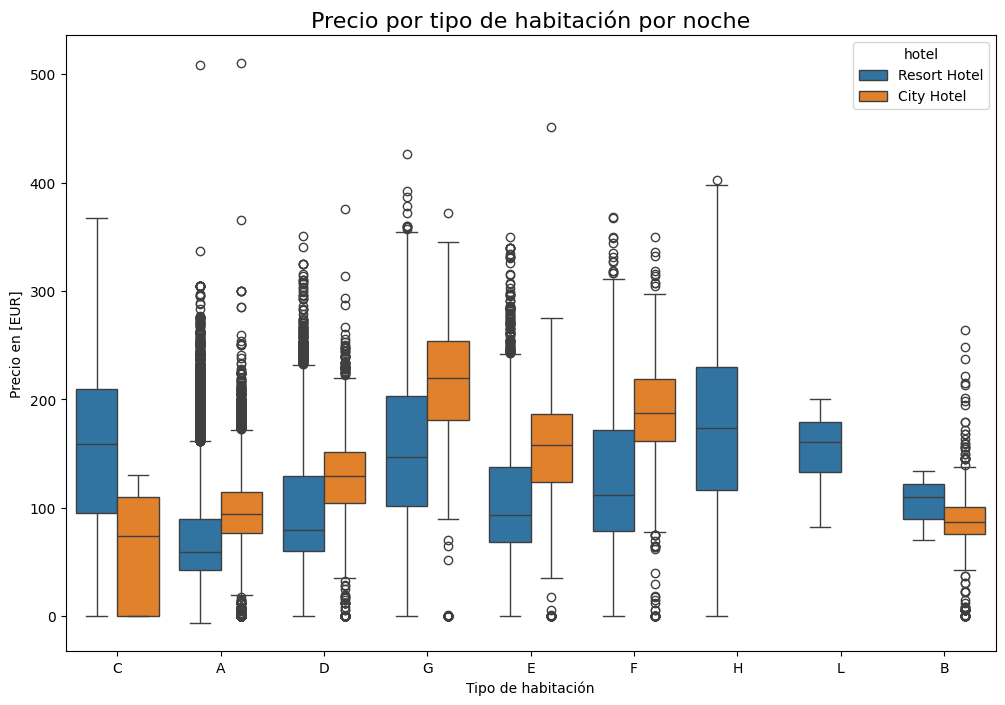

In [ ]:
cuanto_se_paga = df[df[ 'is_canceled' ] == 0 ]
plt. figure (figsize= ( 12 , 8 ))
sns.boxplot(x= 'reserved_room_type' , y= 'adr' , data=cuanto_se_paga, hue= 'hotel' )
plt.title( 'Precio por tipo de habitación por noche' , fontsize= 16 )
plt.xlabel( 'Tipo de habitación' )
plt.ylabel( 'Precio en [EUR]' )
plt.show()


Text(0.5, 1.0, 'Alo de llegada, Anticipo y Cancelaciones')

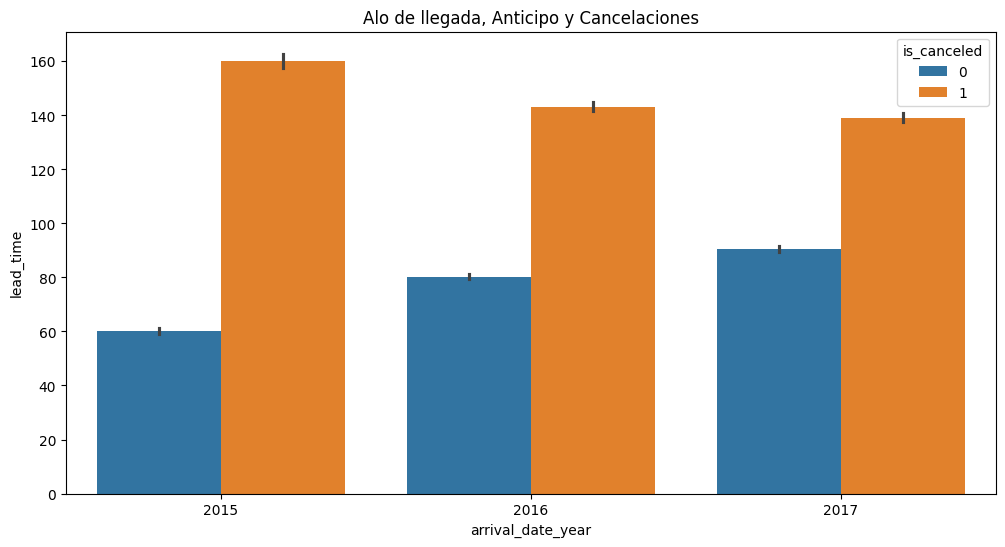

In [ ]:
plt.figure(figsize= ( 12 , 6 ))
sns.barplot(x= 'arrival_date_year' , y= 'lead_time' , hue= 'is_canceled' , data = df)
plt.title ( 'Alo de llegada, Anticipo y Cancelaciones' )

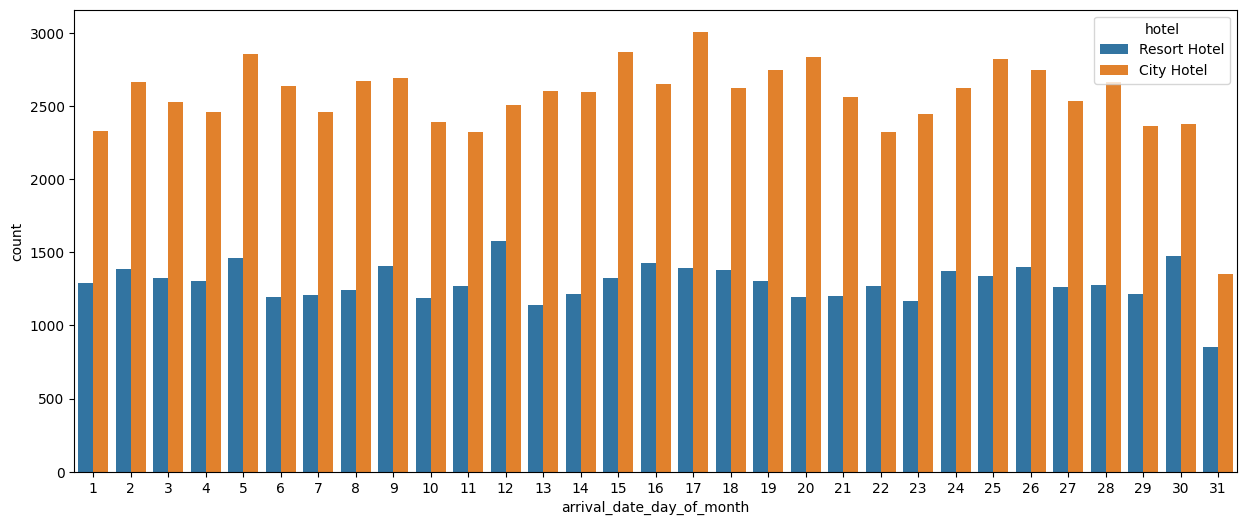

In [ ]:
plt.figure(figsize = ( 15 , 6 ))
sns.countplot(data = df, x = 'arrival_date_day_of_month' , hue = 'hotel' )
plt.show()

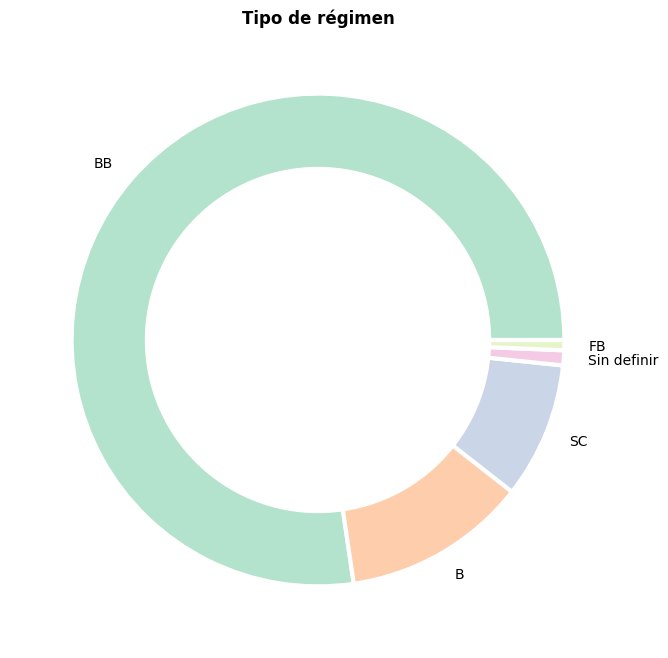

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

etiquetas_comida = ['BB', 'B', 'SC', 'Sin definir', 'FB']
tamaño = df['meal'].value_counts()

plt.figure(figsize=(8, 8))
cmap = plt.get_cmap("Pastel2")
colores = cmap(np.arange(len(etiquetas_comida)) * 1)

mi_círculo = plt.Circle((0, 0), 0.7, color='white')

plt.pie(
    tamaño,
    labels=etiquetas_comida,  # <-- inglés
    colors=colores,           # <-- inglés
    wedgeprops={              # <-- inglés
        'linewidth': 3,       # <-- inglés
        'edgecolor': 'white'  # <-- inglés
    }
)

p = plt.gcf()
p.gca().add_artist(mi_círculo)
plt.title('Tipo de régimen', weight='bold')  # <-- inglés
plt.show()


In [ ]:
fecha_reserva_España = df[df[ 'country' ] == "ESP" ][df[ 'is_canceled' ] == 0 ][
'arrival_date_year' ].value_counts().reset_index()
fecha_reserva_España.columns = [ 'Año' , 'N° Reservas' ]
fecha_reserva_España


/tmp/ipython-input-3703833142.py:1: UserWarning:

Boolean Series key will be reindexed to match DataFrame index.



,Año,N° Reservas
0,2016,2850
1,2015,1800
2,2017,1741


<Axes: xlabel='Año', ylabel='N° Reservas'>

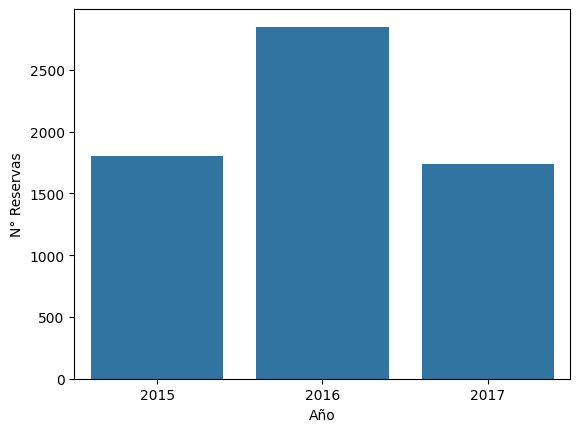

In [ ]:
sns.barplot(x = "Año" , y = "N° Reservas" , data = fecha_reserva_España)

In [ ]:
fecha_reserva_Perú = df[df[ 'country' ] == "PER" ][df[ 'is_canceled' ] == 0 ] [
'arrival_date_year' ].value_counts().reset_index()
fecha_reserva_Perú.columns = [ 'Año' , 'N° Reservas' ]
fecha_reserva_Perú

/tmp/ipython-input-175907150.py:1: UserWarning:

Boolean Series key will be reindexed to match DataFrame index.



,Año,N° Reservas
0,2017,11
1,2016,10
2,2015,2


<Axes: xlabel='Año', ylabel='N° Reservas'>

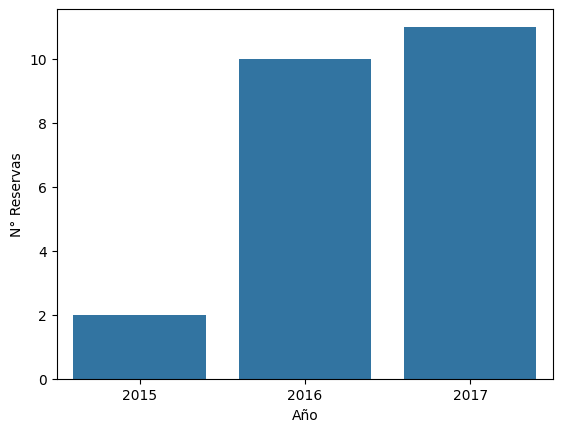

In [ ]:
sns.barplot(x = "Año" , y = "N° Reservas" , data = fecha_reserva_Perú)

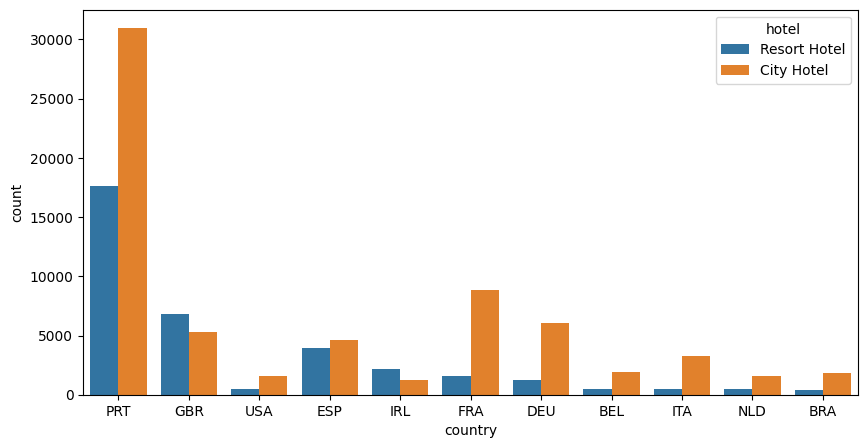

In [ ]:
recuentos = df['country'].value_counts()

plt.subplots(figsize=(10, 5))
sns.countplot(
    x='country',
    hue='hotel',  # en inglés
    data=df[df['country'].isin(recuentos[recuentos > 2000].index)]
)
plt.show()

In [ ]:
cuenta = df[ 'country' ].value_counts()
cuenta

,count
country,
PRT,48590
GBR,12129
FRA,10415
ESP,8568
DEU,7287
...,...
MRT,1
KIR,1
SDN,1


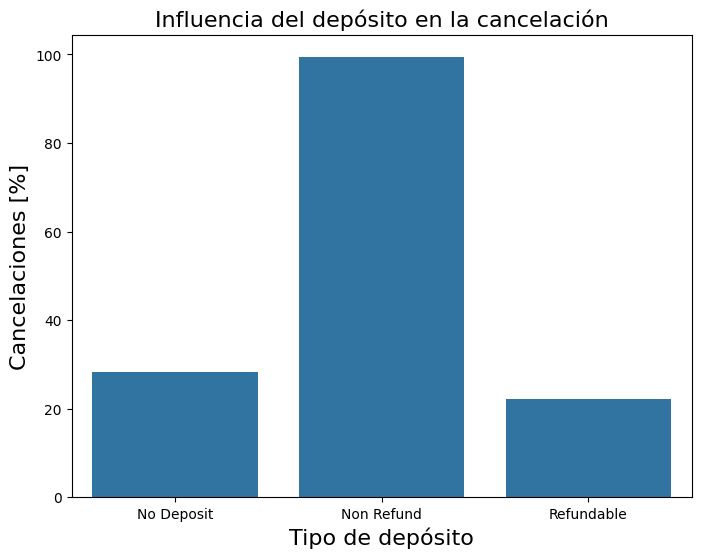

In [ ]:
deposit_cancel_data = df.groupby( "deposit_type" )[ "is_canceled" ].describe()
plt.figure(figsize=( 8 , 6 ))
sns.barplot(x=deposit_cancel_data.index, y=deposit_cancel_data [ "mean" ] * 100 )
plt.title( "Influencia del depósito en la cancelación" , fontsize= 16 )
plt.xlabel( "Tipo de depósito" , fontsize= 16 )
plt.ylabel( "Cancelaciones [%]" , fontsize= 16 )
plt.show()

In [ ]:
#Paso 13. Limpieza de datos:
print(df.isnull().sum())

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [ ]:
df[[ "children" , "country" , "agent" , "company" ]].describe(include= "all" )

,children,country,agent,company
count,119386.000000,118902,103050.000000,6797.000000
unique,NaN,177,NaN,NaN
top,NaN,PRT,NaN,NaN
freq,NaN,48590,NaN,NaN
mean,0.103890,NaN,86.693382,189.266735
std,0.398561,NaN,110.774548,131.655015
min,0.000000,NaN,1.000000,6.000000
25%,0.000000,NaN,9.000000,62.000000
50%,0.000000,NaN,14.000000,179.000000
75%,0.000000,NaN,229.000000,270.000000


In [ ]:
df = df.drop([ 'company' , 'agent' ], axis= 1 )

In [ ]:
df1 = df.dropna (subset=[ 'country' , 'children' ], axis = 0 )

In [ ]:
print(df1.isnull().sum())

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests   

In [ ]:
df[ "country" ].replace(np.nan, "PRT" , inplace= True )

/tmp/ipython-input-3303048619.py:1: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





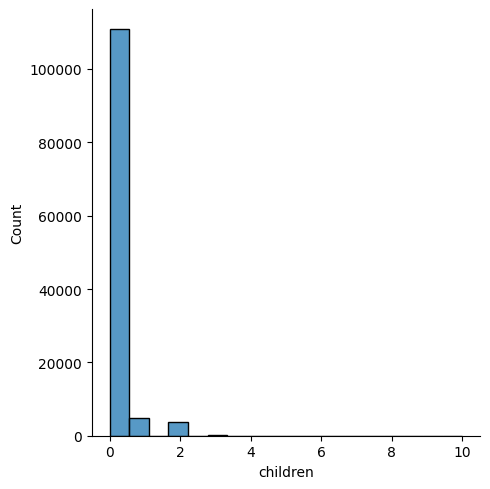

In [ ]:
sns.displot(df[ "children" ])

In [ ]:
media = df[ 'children' ].mean()
mediana = df[ 'children' ].median()
moda = df[ 'children' ].mode()
sesgo = df[ 'children' ].kurt()

print ( "La media es:" , media)
print ( "La mediana es:" , mediana)
print ( "La moda es:" , moda)
print ( "El sesgo es:" , sesgo)


La media es: 0.10388990333874994
La mediana es: 0.0
La moda es: 0    0.0
Name: children, dtype: float64
El sesgo es: 18.673692362954903


In [ ]:
df[ "children" ].replace(np.nan, 0 , inplace= True )
print(df.isnull().sum())


hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests   

/tmp/ipython-input-1723440731.py:1: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





In [ ]:
#Paso 13. Tipos de datos:
df[[ "children" ]] = df[[ "children" ]].astype( "int" )
df[ 'reservation_status_date' ] = pd.to_datetime(df[ 'reservation_status_date' ])
df.dtypes


,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [ ]:
#Paso 14. Datos inconsistentes:
filter = (df['children'] == 0) & (df['adults'] == 0) & (df['babies'] == 0)
sum(filter)


180

In [ ]:
df = df[~ filter ]
df.shape


(119210, 30)

In [ ]:
#Total de huéspedes:
df[ 'Total_Guests' ] = df[ 'adults' ] + df[ 'children' ]
#Comprobamos que efectivamente no hay ningún registro que sume 0:
filter = df.Total_Guests != 0
df.drop( "Total_Guests" , axis= 1 , inplace= True )
sum ( filter )


119210

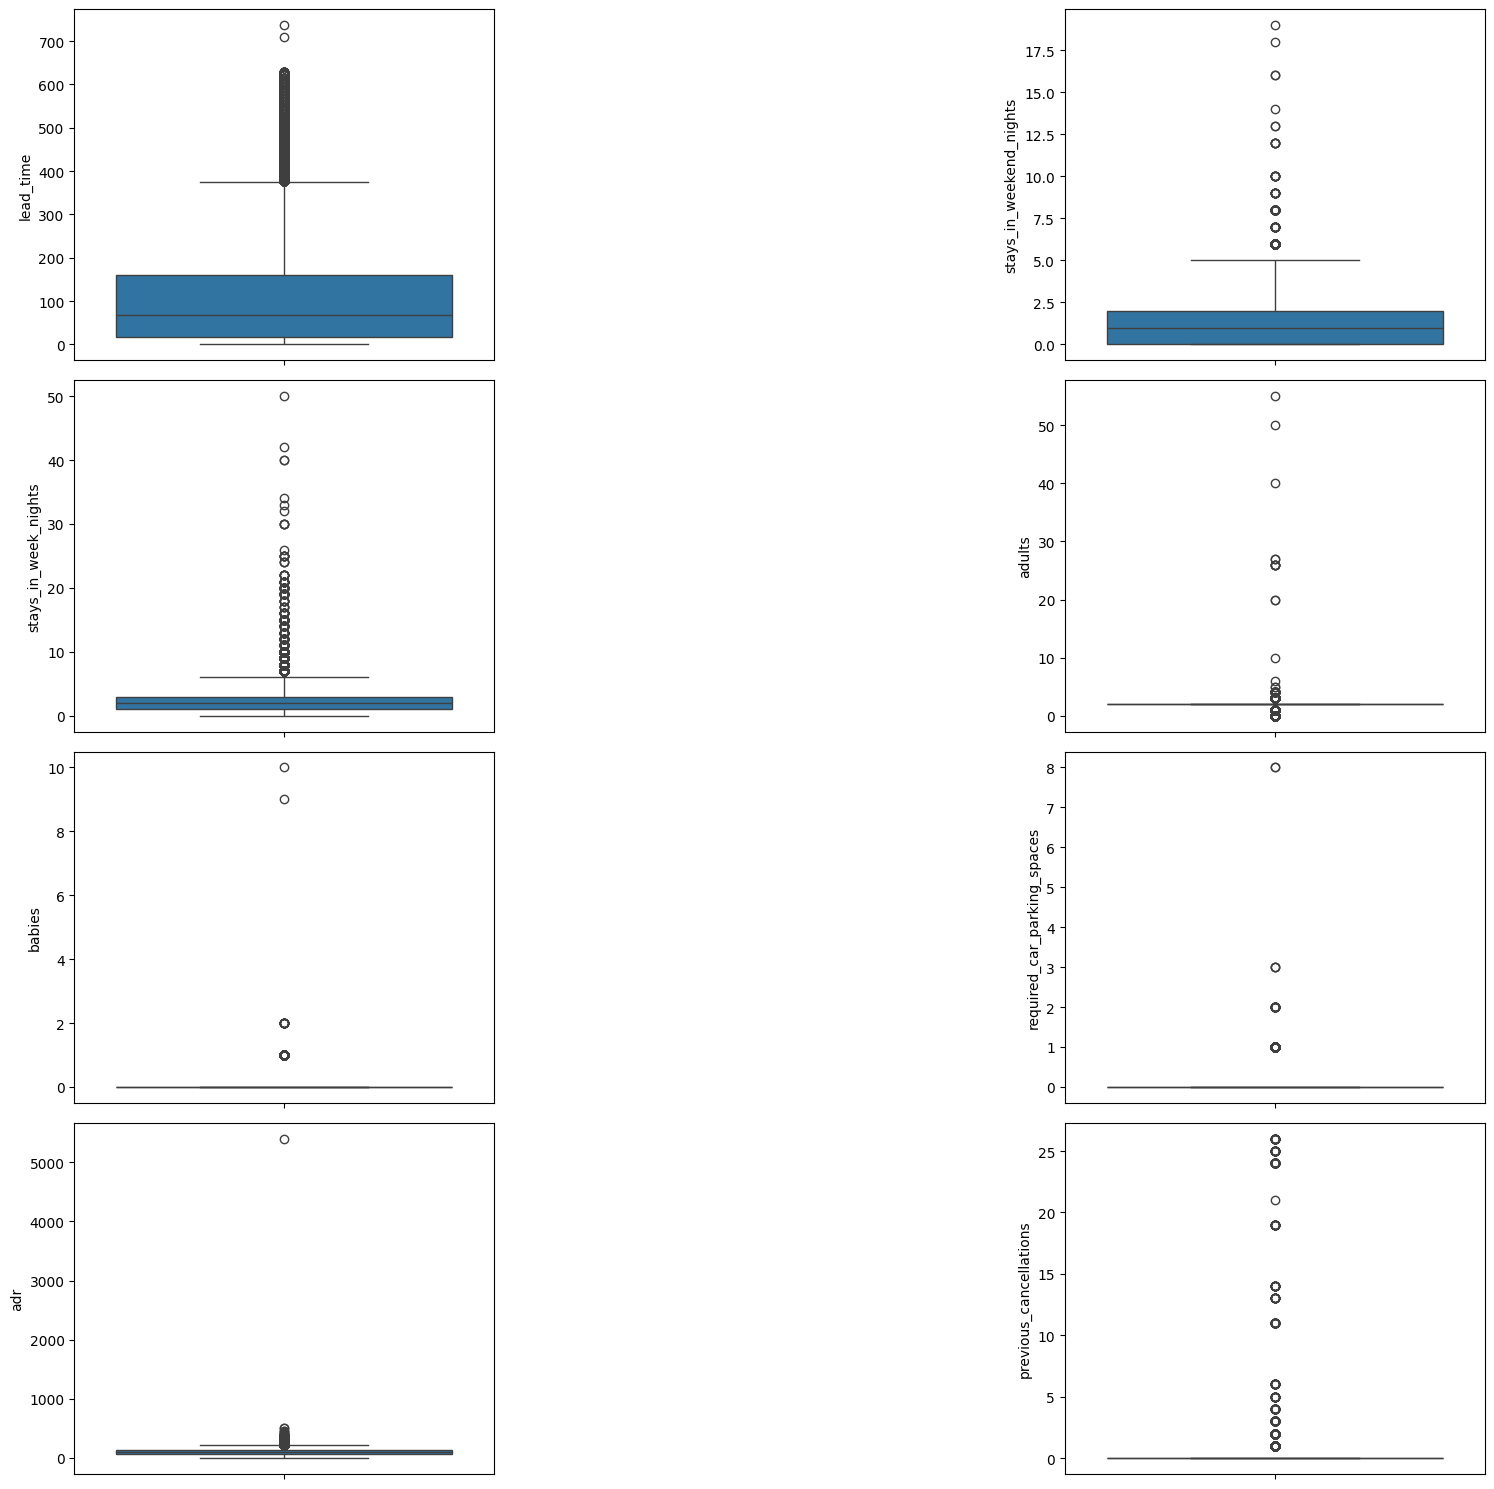

In [ ]:
#Paso 15. Datos atípicos:
columnas = [ 'lead_time' , 'stays_in_weekend_nights' , 'stays_in_week_nights' , 'adults' ,
            'babies' , 'required_car_parking_spaces' , 'adr' , 'previous_cancellations' ]
n = 1
plt.figure(figsize = ( 20 , 15 ))

for columna in columnas:
  plt.subplot( 4 , 4 , n)
  n = n + 2
  sns.boxplot (y=df[columna])
  plt.tight_layout()


<Axes: ylabel='Frequency'>

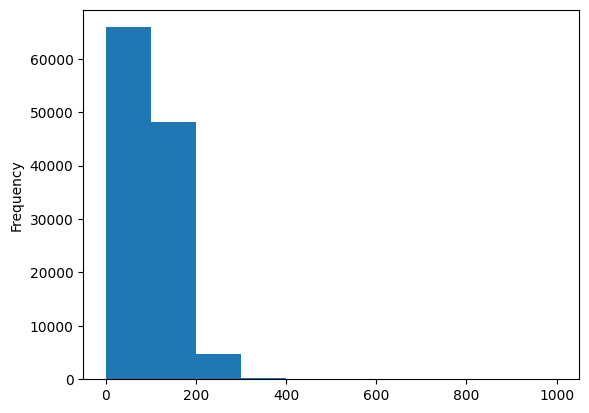

In [ ]:
df.loc[df.lead_time > 400 , 'lead_time' ] = 400
df.loc[df.stays_in_week_nights >= 5 , 'stays_in_week_nights' ] = 5
df.loc[df.stays_in_week_nights > 20 , 'stays_in_week_nights' ] = 20
df.loc[df.adults > 10 , 'adults' ] = 10
df.loc[df.babies > 8 , 'babies' ] = 0
df.loc[df.required_car_parking_spaces > 5 , 'required_car_parking_spaces' ] = 0
df.loc[df.adr > 1000 , 'adr' ] = 1000
df.loc[df.adr < 30 , 'adr' ] = 0
df[ 'adr' ].plot(kind = 'hist' )


In [ ]:
#Seleccionar columnas:
select_df = df[[ 'lead_time' , 'arrival_date_year' , 'stays_in_weekend_nights' , 'adults' ,
                'is_repeated_guest' , 'previous_cancellations' , 'required_car_parking_spaces' ,
                'adr' ]]

#Especificar el modelo que se va a utilizar:
model = LocalOutlierFactor(n_neighbors = 30 )

#Ajustar el modelo:
y_pred = model.fit_predict(select_df)
y_pred
#Filtrar los índices de los outliers
outlier_index = (y_pred == - 1 ) #los valores negativos son outliers

#Filtrar los valores de los outliers en el dataframe
outlier_values = select_df.iloc[outlier_index]
outlier_values


/usr/local/lib/python3.11/dist-packages/sklearn/neighbors/_lof.py:322: UserWarning:

Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.



,lead_time,arrival_date_year,stays_in_weekend_nights,adults,is_repeated_guest,previous_cancellations,required_car_parking_spaces,adr
1,400,2015,0,2,0,0,0,0.00
14,37,2015,0,2,0,0,0,94.71
21,72,2015,2,2,0,0,0,84.67
22,72,2015,2,2,0,0,0,84.67
30,118,2015,4,1,0,0,0,62.00
...,...,...,...,...,...,...,...,...
119317,188,2017,0,3,0,0,0,129.60
119321,181,2017,0,2,0,0,0,119.25
119359,63,2017,1,2,0,0,0,133.50
119366,210,2017,2,2,0,0,0,85.59


In [ ]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type',
       'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

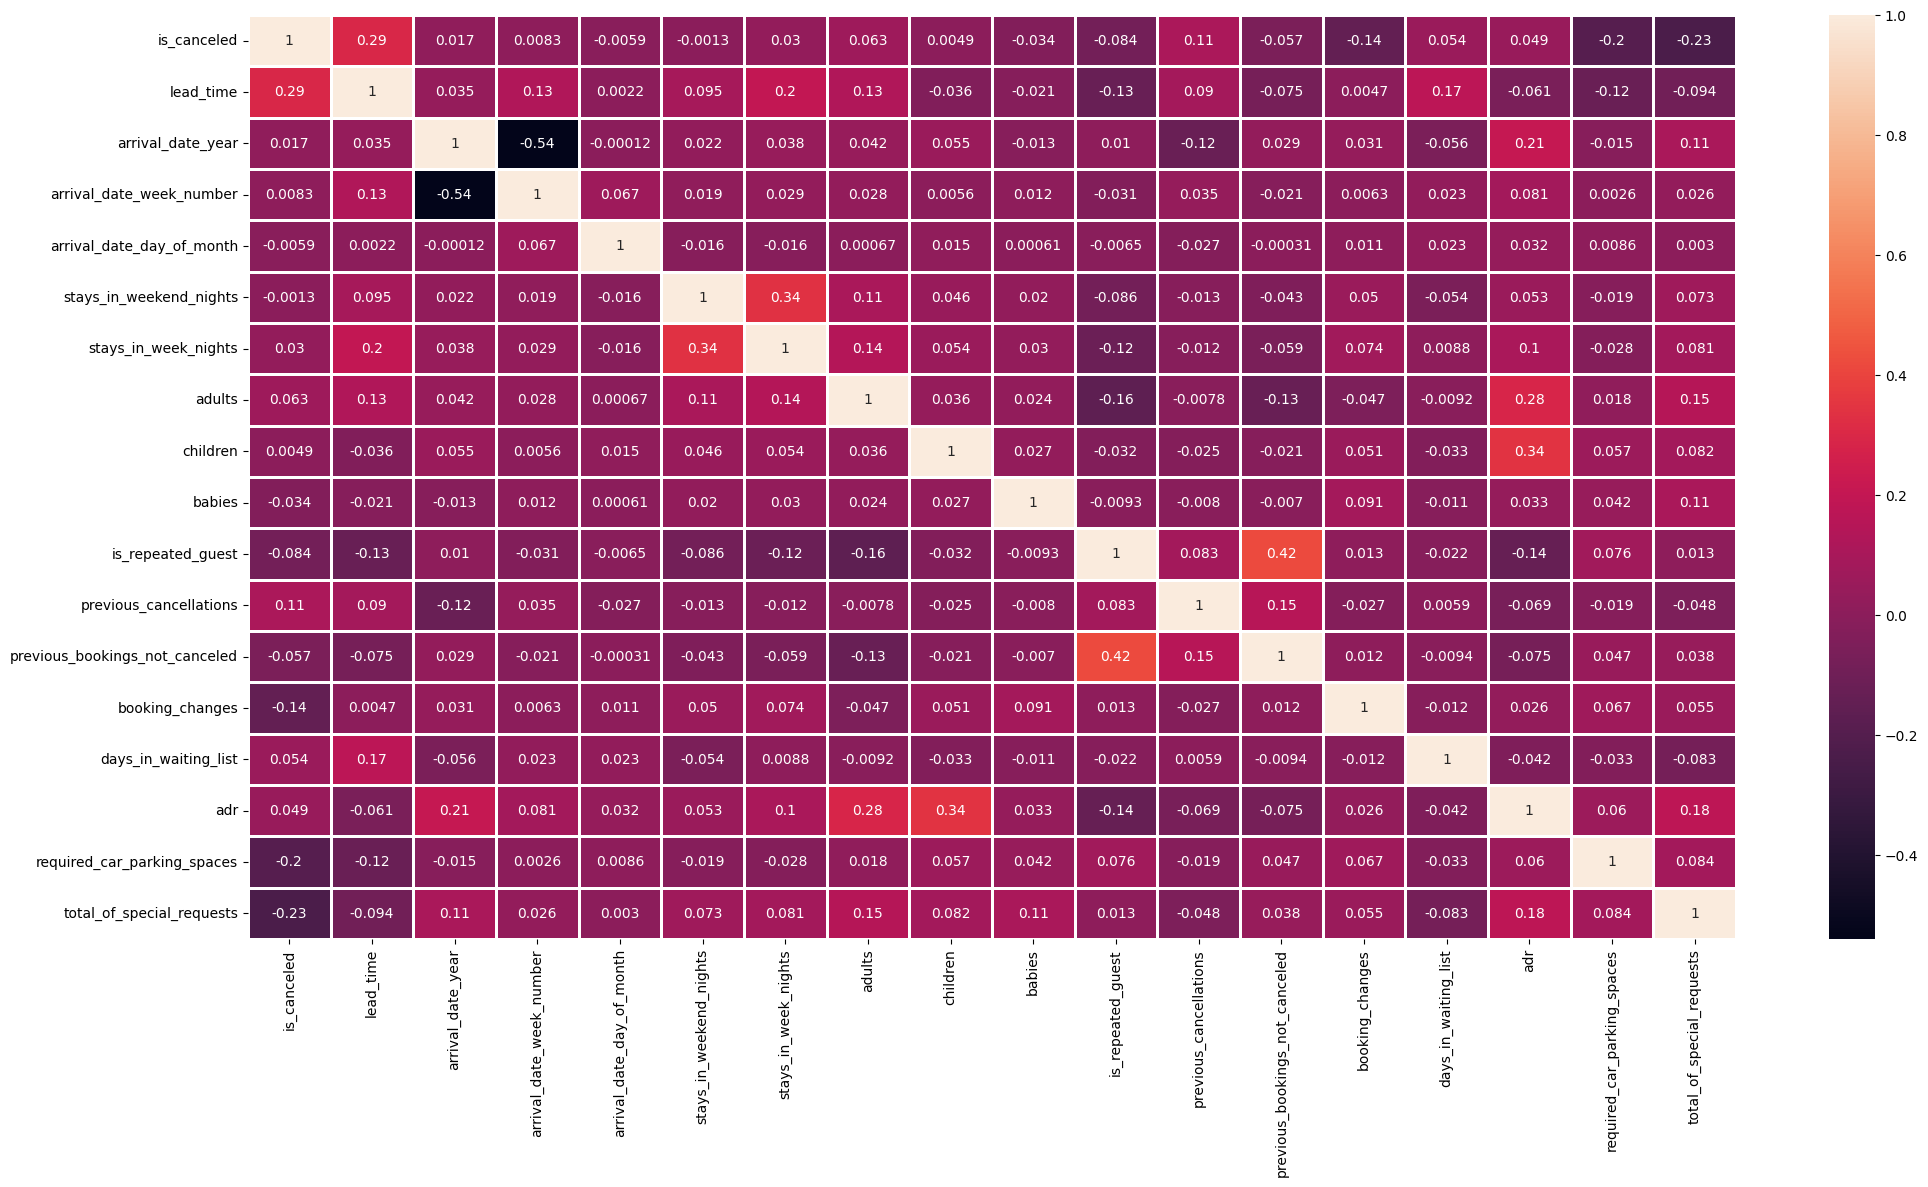

In [ ]:
#Paso 16. Datos redundantes:
df_numeric = df.select_dtypes(include=[ 'int64' , 'float64' ])
corr = df_numeric.corr()
plt.figure(figsize = ( 24 , 12 ))
sns.heatmap(corr, annot = True , linewidths = 1 )
plt.show()


In [ ]:
#Paso 17. Datos duplicados:
#Contando los duplicados de todo el dataframe:
df.duplicated().sum()

np.int64(32035)

In [ ]:
#Permite ver las filas duplicadas de todo el dataframe
df.loc[df.duplicated(), :]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,assigned_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,A,0,No Deposit,0,Transient,98.00,0,1,Check-Out,2015-07-03
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,A,1,No Deposit,0,Transient,84.67,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,E,0,No Deposit,0,Transient,137.00,0,1,Check-Out,2015-07-07
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,D,0,No Deposit,0,Transient,97.00,0,0,Canceled,2015-07-01
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,A,0,No Deposit,0,Transient,109.80,0,3,Check-Out,2015-07-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119349,City Hotel,0,186,2017,August,35,31,0,3,2,...,D,0,No Deposit,0,Transient,126.00,0,2,Check-Out,2017-09-03
119352,City Hotel,0,63,2017,August,35,31,0,3,3,...,D,0,No Deposit,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119353,City Hotel,0,63,2017,August,35,31,0,3,3,...,D,0,No Deposit,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119354,City Hotel,0,63,2017,August,35,31,0,3,3,...,D,0,No Deposit,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03


In [ ]:
#Si se quisiera eliminar los duplicados
df_drop = df.drop_duplicates()
df_drop.shape


(87175, 30)

In [ ]:
 #Paso 18. Transformaciones a los datos:
#18.1. Normalización:
df_normalize = df.copy()
scaler = MinMaxScaler()
df_normalize[[ 'lead_time' , 'arrival_date_year' , 'arrival_date_day_of_month' , 'stays_in_weekend_nights' ,
              'stays_in_week_nights' , 'adr' ]] = scaler.fit_transform(df_normalize[[ 'lead_time' ,
              'arrival_date_year' , 'arrival_date_day_of_month' , 'stays_in_weekend_nights' , 'stays_in_week_nights' , 'adr' ]])

df_normalize[[ 'lead_time' , 'arrival_date_year' , 'arrival_date_day_of_month' , 'stays_in_weekend_nights' ,
              'stays_in_week_nights' , 'adr' ]].tail( 10 )


,lead_time,arrival_date_year,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adr
119380,0.1100,1.0,1.000000,0.052632,0.6,0.14075
119381,0.4700,1.0,1.000000,0.105263,0.6,0.09900
119382,0.3375,1.0,0.966667,0.105263,0.8,0.20900
119383,0.4100,1.0,1.000000,0.105263,0.8,0.08760
119384,0.0525,1.0,0.966667,0.105263,1.0,0.09614
119385,0.0575,1.0,0.966667,0.105263,1.0,0.09614
119386,0.2550,1.0,1.000000,0.105263,1.0,0.22543
119387,0.0850,1.0,1.000000,0.105263,1.0,0.15771
119388,0.2725,1.0,1.000000,0.105263,1.0,0.10440
119389,0.5125,1.0,0.933333,0.105263,1.0,0.15120


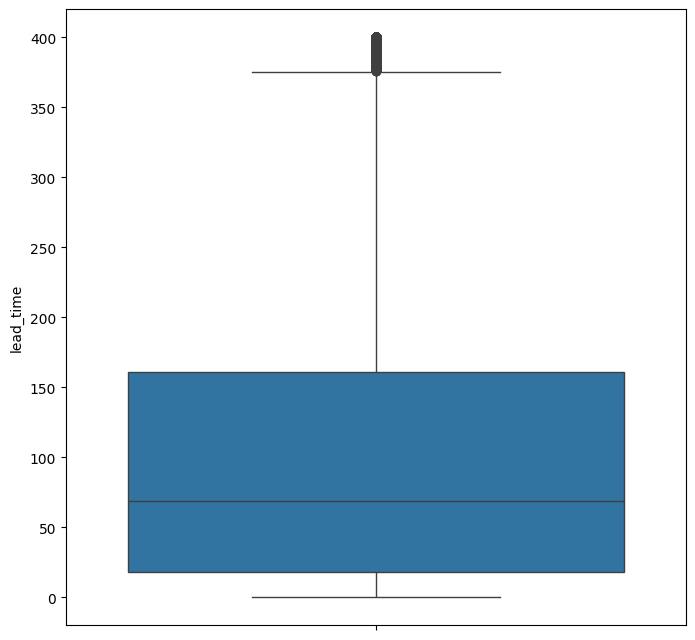

In [ ]:
#18.2. Discretización:
fig = plt.figure(figsize=( 8 , 8 ))
sns.boxplot(y=df[ "lead_time" ])
plt.show()


In [ ]:
nivelAntelacion = [ 'Ninguno' , '2-3Semanas' , '1Mes' , '2Meses' , '3Meses' , 'Mas3Meses' ]
df[ 'tiempo_de_entrega_clasificado' ] = pd.cut(x = df[ 'lead_time' ],
                      bins = [ 0 , 1 , 21 , 30 , 60 , 120 , 737 ],
                      labels = nivelAntelacion, include_lowest = True )
df[[ 'lead_time' , 'tiempo_de_entrega_clasificado' ]].head( 10 )


,lead_time,tiempo_de_entrega_clasificado
0,342,Mas3Meses
1,400,Mas3Meses
2,7,2-3Semanas
3,13,2-3Semanas
4,14,2-3Semanas
5,14,2-3Semanas
6,0,Ninguno
7,9,2-3Semanas
8,85,3Meses
9,75,3Meses


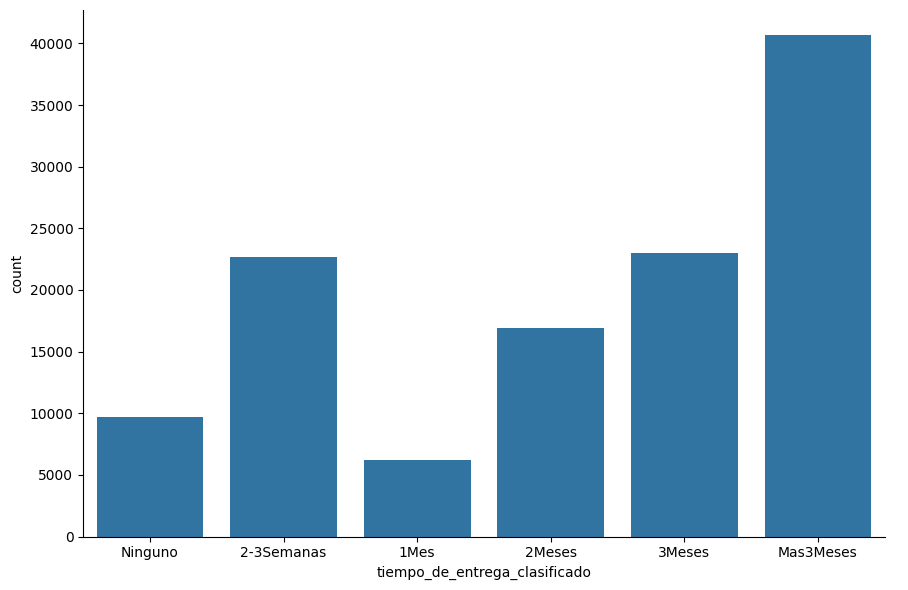

In [ ]:
sns.catplot(x= "tiempo_de_entrega_clasificado" , kind= "count" , data=df, height= 6 , aspect= 1.5 )
plt.show()


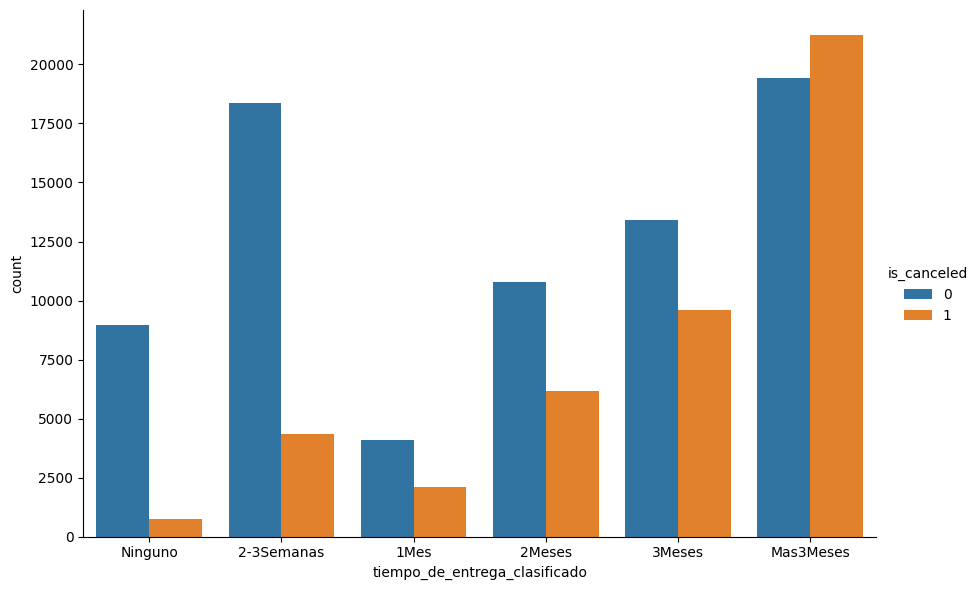

In [ ]:
sns.catplot(x="tiempo_de_entrega_clasificado", hue="is_canceled", kind="count", data=df, height=6, aspect=1.5)
plt.show()


In [ ]:
# Numerar 1 a 1
df_cat[ 'hotel' ] = df_cat[ 'hotel' ]. map ({ 'Resort Hotel' : 0 , 'City Hotel' : 1 })
df_cat[ 'reserved_room_type' ] = df_cat[ 'reserved_room_type' ]. map ({ 'A' : 0 , 'B' : 1 , 'C' : 2 , 'D' : 3 , 'E' : 4 , 'F' : 5 , 'G' : 6 , 'H' : 7 , 'L' : 8 })
df_cat.head()
df_cat.columns

Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'assigned_room_type',
       'deposit_type', 'customer_type', 'reservation_status',
       'reservation_status_date'],
      dtype='object')

In [ ]:
df_cat = pd.get_dummies(df_cat, columns = [ "distribution_channel" ])
df_cat = pd.get_dummies(df_cat, columns = [ "customer_type" ])
df_cat = pd.get_dummies(df_cat, columns = [ "deposit_type" ])
df_cat.head()


,hotel,arrival_date_month,meal,country,market_segment,reserved_room_type,assigned_room_type,reservation_status,reservation_status_date,distribution_channel_Corporate,...,distribution_channel_GDS,distribution_channel_TA/TO,distribution_channel_Undefined,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable
0,0,July,BB,PRT,Direct,2.0,C,Check-Out,2015-07-01,False,...,False,False,False,False,False,True,False,True,False,False
1,0,July,BB,PRT,Direct,2.0,C,Check-Out,2015-07-01,False,...,False,False,False,False,False,True,False,True,False,False
2,0,July,BB,GBR,Direct,0.0,C,Check-Out,2015-07-02,False,...,False,False,False,False,False,True,False,True,False,False
3,0,July,BB,GBR,Corporate,0.0,A,Check-Out,2015-07-02,True,...,False,False,False,False,False,True,False,True,False,False
4,0,July,BB,GBR,Online TA,0.0,A,Check-Out,2015-07-03,False,...,False,True,False,False,False,True,False,True,False,False


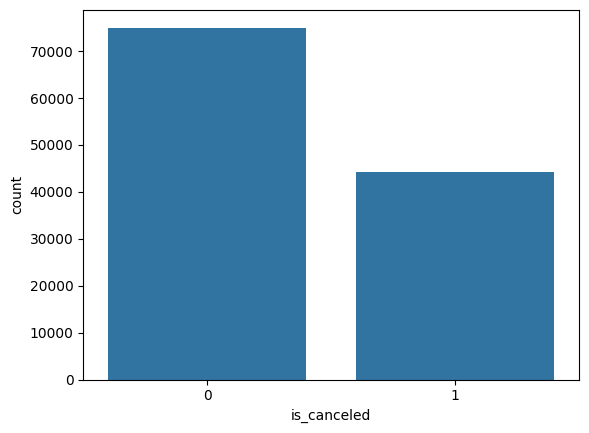

In [ ]:
#Variable si la reserva fue cancelada o no
sns.countplot(data=df, x = 'is_canceled' )
plt.show()


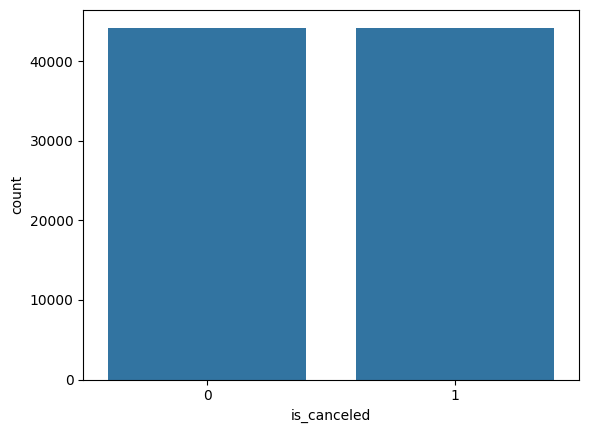

In [ ]:
from sklearn.utils import resample

# Contar las clases:
count_class_No, count_class_Yes = df[ "is_canceled" ].value_counts()

# Dividir los dataframes por clases:
df_class_No = df[df[ "is_canceled" ] == 0 ]
df_class_Yes = df[df[ "is_canceled" ] == 1 ]

# Submuestrear la clase mayoritariamente No:
no_downsampled = resample(df_class_No,
                      replace= False , # muestra sin reemplazo
                       n_samples = count_class_Yes, # Número de muestras a generar
                       random_state = 27 ) # resultados reproducibles
                      # combinar dataframes
df_sample = pd.concat([df_class_Yes, no_downsampled])
sns.countplot(data=df_sample, x = 'is_canceled' )
plt.show()



**Conclusiones:**

1. El tipo de hotel influye significativamente en el comportamiento de los clientes ya que las reservas en el City Hotel son más frecuentes que en el Resort Hotel, especialmente en temporada alta (junio-agosto), además, las tarifas promedio (adr) tienden a ser más elevadas en el Resort Hotel durante ciertos meses, lo que sugiere una estrategia de precios diferenciada según el tipo de hotel y temporada.

2. El tiempo en que se hace la reserva está relacionado con la probabilidad de cancelación. La variable "lead_time" nos muestra que las reservas hechas con más de tres meses de antelación tienen una mayor tasa de cancelación, lo cuál podría deberse a cambios en los planes de los clientes o a políticas de cancelación flexibles, por lo que podrían  ajustarse condiciones de reservas anticipadas.

3. Los datos y su calidad no son los mejoresz para garantizar un buen análisis. Se encontraron múltiples problemas como datos faltantes, valores atípicos, tipos de datos incorrectos y registros inconsistentes (por ejemplo, reservas sin huéspedes), por lo que tuvo que hacerse un gran trabajo de limpieza de datos para poder analizar datos y encontrar conclusiones.

4. La demanda de los huéspedes puede ser sectorizada por países, ya que algunos países muestran mayor demanda en comparación con otros. Por ejemplo, "Portugal (PRT)" es el país con mayor número de huéspedes, seguido por otros países europeos.Este análisis geográfico nos permite identificar el público objetivo o más demandante.

5. La mayoría de los huéspedes optan por el régimen Bed & Breakfast (BB) y también por el tipo de habitación A, lo que permite que la empresa identifique los servicios con mayor demanda para sugerir promociones, combos y tener una mayor cantidad de estos servicios para garantizar una mayor compra y/o reserva.